# ECE 3715 Mini-Project 1

## Probability, Bayes, and Discrete Random Variables
Professor: Dr. Nir Regev

Team Members: Brandon Chie, Octavio Reyna, William Hsu

Start Date: September 18, 2026

Due Date: October 9, 2026
## Objective
Use probability theory and Python simulations to analyze a wireless communication link. Each bit is independently corrupted by the channel with probability $p$. We will determine how these corrupted bits affect packet errors and retransmissions.

In [1]:

import time #Used for the timer function
import numpy #Used for easy array manipulation functions & RNG
from scipy import stats #Used for theoretical probabilities of binomial, poisson and geometric distribution
import matplotlib.pyplot as plt #Used for plotting graphs
import mp1lib as func #Functions from mp1lib.py file

T_START = time.time()     #Timer begins for total notebook time

SEED = 17                  #Our chosen seed number to keep rng consistent
rng = numpy.random.default_rng(SEED)
rng1, rng2, rng3, rng4, rng5, rng6, rng7, rng8 = rng.spawn(8)

In [2]:
#Handcheckable Test
#Assert confirms that the comparison is true, if not assert error will pop up

#For testing purposes we will use a different rng so it doesn't interfere with our current one
rng_test = numpy.random.default_rng(20)

#Setting a test array to test BSC function
b = numpy.array([0, 1, 0, 1, 0, 1, 1])
#Testing array with 0% probability, no bits will get corrupted
assert numpy.array_equal(func.bsc(b, 0, rng_test), b) #array_equal checks if both arrays are equal to each other and outputs t/f
#Testing array with 100% probability, will flip bit array
assert numpy.array_equal(func.bsc(b, 1, rng_test), 1 - b) #1-b Preforms a bit flip
print("BSC Test:        ", b ,"\n0% Probability:  ",func.bsc(b, 0, rng_test), "\n100% Probability:",func.bsc(b, 1.0, rng_test))

#Packet Error Test
#Testing packet error with 0% probability, each packet should contain 0 errors
assert numpy.all(func.packet_errors(5, 1000, 0, rng_test) == 0)
#Testing packet error with 100% probability, each packet should contain max amount of errors
assert numpy.all(func.packet_errors(5, 1000, 1.0, rng_test) == 1000)
print("Packet Errors Test:\n" "0% probability:  ", func.packet_errors(5, 1000, 0, rng_test), "\n100% probability:", func.packet_errors(5, 1000, 1, rng_test))

#Clean Attempt Test
#Testing attempts until clean with 100% probability of successful transmission, all test should be 1
assert numpy.all(func.attempts_until_clean(5, 1, rng_test) == 1)
#Testing 100,000 trials to make sure that our minimum attempt is 1 not 0, if not assert error will occur
assert func.attempts_until_clean(100000, 0.1, rng_test).min() >= 1
print("Clean Attempts Test:\n""q=1:", func.attempts_until_clean(5, 1, rng_test))

#TV Distance Test
#Identical test should have a 0 distance
assert func.tv_distance([0.2, 0.3, 0.5],[0.2, 0.3, 0.5]) == 0
#Complete opposite test should have max distance
assert func.tv_distance([1, 0, 0],[0, 0, 1]) == 1

print("TV Distance Test:\n""Identical distributions:",func.tv_distance([0.2, 0.3, 0.5], [0.2, 0.3, 0.5]),"\nOpposite distributions: ",
    func.tv_distance([1, 0, 0], [0, 0, 1]))

print("\nAll functions work as expected!")

BSC Test:         [0 1 0 1 0 1 1] 
0% Probability:   [0 1 0 1 0 1 1] 
100% Probability: [1 0 1 0 1 0 0]
Packet Errors Test:
0% probability:   [0 0 0 0 0] 
100% probability: [1000 1000 1000 1000 1000]
Clean Attempts Test:
q=1: [1 1 1 1 1]
TV Distance Test:
Identical distributions: 0.0 
Opposite distributions:  1.0

All functions work as expected!


## Step 1: The Sample Space and The Axioms

**Objective:** Analyze the probabilities of different event spaces (A, B, C) for a 4 bit packet.

- **A**: At lest one error among the first two bits
- **B**: Exactly two errors in the packet
- **C**: The fourth bit is corrupted

For a 4 bit packet there are $2^4=16$ unique patterns. The probability of a specific case with $k$ errors is


$$P(\text{patterns})=p^k(1-p)^{4-k}$$


- **k** = number of corrupted bits (the error)
- **p** = probability of corruption

The probability of the 16 patterns should sum up to 1. 

**Process:** We will generate all 16 possibilities for a 4 bit packet and determine the probabilities of 3 event conditions (A, B and C). Each bit has a 10% probability of being corrupted (**p** = 0.1). A 1 will represent the corrupted bit while a 0 represents an uncorrupted bit.

In [3]:
from itertools import product

p1 = 0.1 #10% probability for step 1

#Creating an array of all 16 patterns
patterns = numpy.array(list(product([0, 1], repeat=4)))#An array of all possible outcomes for 4 bits

#Figuring the number of errors in each packet by summing the bits in each row
error_count = patterns.sum(axis=1) #An array of all error counts in each packet

#Probability of a specific case happening
prob_form = (p1 ** error_count * (1 - p1) ** (4 - error_count))

print(patterns)
print("Sum of probabilities:", prob_form.sum()) #Sum of all probabilities should be 1

[[0 0 0 0]
 [0 0 0 1]
 [0 0 1 0]
 [0 0 1 1]
 [0 1 0 0]
 [0 1 0 1]
 [0 1 1 0]
 [0 1 1 1]
 [1 0 0 0]
 [1 0 0 1]
 [1 0 1 0]
 [1 0 1 1]
 [1 1 0 0]
 [1 1 0 1]
 [1 1 1 0]
 [1 1 1 1]]
Sum of probabilities: 0.9999999999999999


### Event Space Probabilities
We will hand calculate the event spaces below with 10% probability of a bit being corrupted
$$P(\text{patterns})=p^k(1-p)^{n-k}$$


- **k** = number of corrupted bits (the error)
- **p** = probability of corruption
- **n**: Number of bits

**Event A**: At least one error among the first two bits
$$P([1,0,0,0])=0.1(0.9)^3=0.0729$$
$$P([1,0,0,1])=(0.1)^2(0.9)^2=0.0081$$
$$P([1,0,1,0])=(0.1)^2(0.9)^2=0.0081$$
$$P([1,0,1,1])=(0.1)^3(0.9)=0.0009$$
$$0.0729+0.0081+0.0081+0.0009=0.09$$
$$P([1,1,0,0])=(0.1)^2(0.9)^2=0.0081$$
$$P([1,1,0,1])=(0.1)^3(0.9)^1=0.0009$$
$$P([1,1,1,0])=(0.1)^3(0.9)^1=0.0009$$
$$P([1,1,1,1])=(0.1)^4(0.9)^0=0.0001$$
$$0.0081+0.0009+0.0009+0.0001=0.01$$

Multiply 0.09 * 2 because there are the same amount of possible combinations for the bits [0, 1]
$$P(A)=2 \cdot 0.09+0.01$$

$$P(A)=0.19$$

**Event B:** Exactly two errors in the four bit packet

We can use the Binomial PMF to calculate for all possible packets with 2 errors

Binomial PMF: $$P(B)=\binom{n}{k}p^k(1-p)^{n-k}$$
$$P(B)=\binom{4}{2}p^2(1-p)^{4-2}$$

$$P(B)=\binom{4}{2}(0.1)^2(0.9)^2$$

$$P(B)=6(0.01)(0.81)$$

$$P(B)=0.0486$$

**Event C:** The fourth bit is corrupted

Since each bit has a probability of 10% corruption, the fourth bit will follow the same pattern

$$P(C)=p$$

$$P(C)=0.1$$


In [4]:
#Computing the event space

#A: At least one error among the first two bits
A = patterns[:, 0:2].any(axis=1)

#B: Exactly two errors in the entire packet
B = patterns.sum(axis=1) == 2

# C:The fourth bit is corrupted
C = patterns[:, 3] == 1

#Exact Probabilities of individual events
ProbA_exact = prob_form[A].sum()
ProbB_exact = prob_form[B].sum()
ProbC_exact = prob_form[C].sum()

print("P(A): ", round(ProbA_exact, 4))
print("P(B): ", round(ProbB_exact.sum(), 4))
print("P(C): ", round(ProbC_exact.sum(), 4))

P(A):  0.19
P(B):  0.0486
P(C):  0.1


### Monte Carlo Simulation
Objective: To test our probabilities we will use the Monte Carlo Simulation for all three event (A, B, C). Monte Carlo simulation is a method that runs a random experiment many times (in our simulation $N=10^6$ four bit packets) so we can get a close estimate of each event probability if each bit has a 10% chance of getting corrupted. 

Process:

We will estimate each event probability by dividing the number of packets in the event by the total number of simulated packets:

$$\widehat{P}(Event)=\frac{\text{number packets in }Event}{N}$$

$$\widehat{P}(\text{Event})=
\frac{1}{N}\sum_{i=1}^{N}
\mathbf{1}\{\text{event occurs in trial }i\}$$

Both formulas represent the same thing.

More trials will improve the estimated probabilities but we are doing 1 million packets so we will get close.

In [5]:
#Monte Carlo simulation
N = 10**6 #1 million trials

#Simulate 1 million trials, creates an array of 1 million rows with all 0, run through bsc to simulate corruption
sim_patterns = func.bsc(numpy.zeros((N, 4), dtype=int),p1,rng1) 

#Event Packet checker, stores an array of T/F for each packet, True means it's in the Event
Check_A = sim_patterns[:, 0:2].any(axis=1) #Checks the first two columns of each row if any contain a corrupted bit
Check_B = sim_patterns.sum(axis=1) == 2 #Checks every row if it contains exactly 2 corrupted bits
Check_C = sim_patterns[:, 3] == 1 #Checks the last column if it contains a corrupted bit

#Calculates the probability of each event using the mean. Basically the number of packets in the Event by total trials.
ProbA_sim = Check_A.mean()
ProbB_sim = Check_B.mean()
ProbC_sim = Check_C.mean()

#Output Monte Carlo simulation results
print("Monte Carlo estimates:")
print("P(A): ", round(ProbA_sim, 4))
print("P(B): ", round(ProbB_sim, 4))
print("P(C): ", round(ProbC_sim, 4))

Monte Carlo estimates:
P(A):  0.1905
P(B):  0.0487
P(C):  0.1001


### Event Intersections Exact and Empirical 

An event intersection means that both events occur at the same time. For a triple intersection all three events must occur at the same time. 

It is mathematically below depicted with probability encasing it.

Pairwise Intersections:
$$P(A\cap B) \qquad P(A\cap C) \qquad (B\cap C)$$

Triple Inteserction:
$$P(A\cap B\cap C)$$

In [6]:
#Exact and Empirical Intersection Calculations

#Exact intersection probabilities
ProbAB_exact = prob_form[A & B].sum()
ProbAC_exact = prob_form[A & C].sum()
ProbBC_exact = prob_form[B & C].sum()
ProbABC_exact = prob_form[A & B & C].sum()

#Checking if packets intersect
Check_AB = Check_A & Check_B
Check_AC = Check_A & Check_C
Check_BC = Check_B & Check_C
Check_ABC = Check_A & Check_B & Check_C

#Empirical intersection probabilities
ProbAB_sim = Check_AB.mean()
ProbAC_sim = Check_AC.mean()
ProbBC_sim = Check_BC.mean()
ProbABC_sim = Check_ABC.mean()

#Output the Exact and Empirical Intersection results
print("Intersection probabilities:")
print("              Exact      Empirical")
print("P(A and B):  ", round(ProbAB_exact, 4), "   ", round(ProbAB_sim, 4))
print("P(A and C):  ", round(ProbAC_exact, 4), "    ", round(ProbAC_sim, 4))
print("P(B and C):  ", round(ProbBC_exact, 4), "   ", round(ProbBC_sim, 4))
print("P(A, B, C):  ", round(ProbABC_exact, 4), "   ", round(ProbABC_sim, 4))

Intersection probabilities:
              Exact      Empirical
P(A and B):   0.0405     0.0407
P(A and C):   0.019      0.0191
P(B and C):   0.0243     0.0242
P(A, B, C):   0.0162     0.0163


### Inclusion-Exclusion

An inclusion exclusion means that one or the other event must occur. It can be thought of as an or statement. 

It is mathematically depicted below with probability encasing it.

$$P(A\cup B\cup C)=P(A)+P(B)+P(C)-P(A\cap B)-P(A\cap C)-P(B\cap C)+P(A\cap B\cap C).$$

The full equation shows the inclusion and exclusion method. The method is to add all individual probability togehter. Since adding them together causes overlap we must subtract the three pairwise intersections to remove duplicated counts. Then we must add the triple intersection because the subtraction takes away some counts.

In [7]:
#Inclusion Exclusion Calculation

#Exact or calculation
ProbOR_exact = prob_form[A | B | C].sum()

#Exact inclusion exclusion
ProbIE_exact = (ProbA_exact + ProbB_exact + ProbC_exact - ProbAB_exact - ProbAC_exact - ProbBC_exact + ProbABC_exact)

#Checking if each packet is in the union
Check_union = Check_A | Check_B | Check_C

#Empirical union calculation
ProbOR_sim = Check_union.mean()

#Empirical union calculated with inclusion exclusion
ProbIE_sim = (ProbA_sim + ProbB_sim + ProbC_sim - ProbAB_sim - ProbAC_sim - ProbBC_sim + ProbABC_sim)

#Output Exact and Empircal Results of 
print("Union probabilities:")
print("                         Exact       Empirical")
print("Direct calculation:     ", round(ProbOR_exact, 4),"     ", round(ProbOR_sim, 4))
print("Inclusion-exclusion:    ", round(ProbIE_exact, 4),"     ", round(ProbIE_sim, 4))
print("\nDifference between exact methods:", abs(ProbOR_exact - ProbIE_exact))
print("Difference between empirical methods:", round(abs(ProbOR_sim - ProbIE_sim), 4))

Union probabilities:
                         Exact       Empirical
Direct calculation:      0.271       0.2715
Inclusion-exclusion:     0.271       0.2715

Difference between exact methods: 0.0
Difference between empirical methods: 0.0


### Standard Error and Confirmation

**Objective:** To determine how close the empirical probabilities are to the exact probabilities, we will calculate the standard error and the absolute difference for each event.

The standard error estimates how much the probability can change because of the randomness in the Monte Carlo simulation. For an estimated probability $$\widehat{P}$$ based on $$N=10^6$$ simulated packets, the standard error is

$$SE=\sqrt{\frac{\widehat{P}(1-\widehat{P})}{N}}$$

We will calculate the difference between each empirical probability and its exact probability:

$$\text{difference}=\left|\widehat{P}-P\right|$$

The simulation will be considered close to the exact calculation if the difference is less than or equal to three standard errors:

$$\text{difference}\leq 3SE$$

We will check this condition for the individual events, pairwise intersections, triple intersection, and union. If the condition is true, the empirical probability is within three standard errors of the exact probability. This confirms that the Monte Carlo simulation agrees with the exact probability calculations.

In [8]:
#Array of exact probabilities
exact_probs = numpy.array([ProbA_exact, ProbB_exact, ProbC_exact, ProbAB_exact, ProbAC_exact, ProbBC_exact, ProbABC_exact, ProbOR_exact])

#Array of empirical probabilities
empirical_probs = numpy.array([ProbA_sim, ProbB_sim, ProbC_sim, ProbAB_sim, ProbAC_sim, ProbBC_sim, ProbABC_sim, ProbOR_sim])

#Standard error calculation for emprirical v
standard_errors = numpy.sqrt(empirical_probs * (1 - empirical_probs) / N)

diff = numpy.abs(empirical_probs - exact_probs)

within_three_SE = diff <= 3 * standard_errors

print("Event              Exact       Empirical       Difference       SE         Within 3 SE")
print("A:                 ", round(exact_probs[0], 4), "      ", round(empirical_probs[0], 4), "       ", round(diff[0], 6), "       ", round(standard_errors[0], 6), "    ", within_three_SE[0])
print("B:                 ", round(exact_probs[1], 4), "    ", round(empirical_probs[1], 4), "       ", round(diff[1], 6), "       ", round(standard_errors[1], 6), "    ", within_three_SE[1])
print("C:                 ", round(exact_probs[2], 4), "       ", round(empirical_probs[2], 4), "       ", round(diff[2], 6), "        ", round(standard_errors[2], 6), "      ", within_three_SE[2])
print("A and B:           ", round(exact_probs[3], 4), "    ", round(empirical_probs[3], 4), "       ", round(diff[3], 6), "        ", round(standard_errors[3], 6), "    ", within_three_SE[3])
print("A and C:           ", round(exact_probs[4], 4), "     ", round(empirical_probs[4], 4), "       ", round(diff[4], 6), "       ", round(standard_errors[4], 6), "    ", within_three_SE[4])
print("B and C:           ", round(exact_probs[5], 4), "    ", round(empirical_probs[5], 4), "       ", round(diff[5], 6), "        ", round(standard_errors[5], 6), "    ", within_three_SE[5])
print("A, B, and C:       ", round(exact_probs[6], 4), "    ", round(empirical_probs[6], 4), "       ", round(diff[6], 6), "        ", round(standard_errors[6], 6), "    ", within_three_SE[6])
print("A or B or C:       ", round(exact_probs[7], 4), "     ", round(empirical_probs[7], 4), "       ", round(diff[7], 6), "       ", round(standard_errors[7], 6), "    ", within_three_SE[7])

Event              Exact       Empirical       Difference       SE         Within 3 SE
A:                  0.19        0.1905         0.000496         0.000393      True
B:                  0.0486      0.0487         0.000108         0.000215      True
C:                  0.1         0.1001         7.4e-05          0.0003        True
A and B:            0.0405      0.0407         0.00021          0.000198      True
A and C:            0.019       0.0191         0.000104         0.000137      True
B and C:            0.0243      0.0242         5.1e-05          0.000154      True
A, B, and C:        0.0162      0.0163         5.1e-05          0.000126      True
A or B or C:        0.271       0.2715         0.000466         0.000445      True


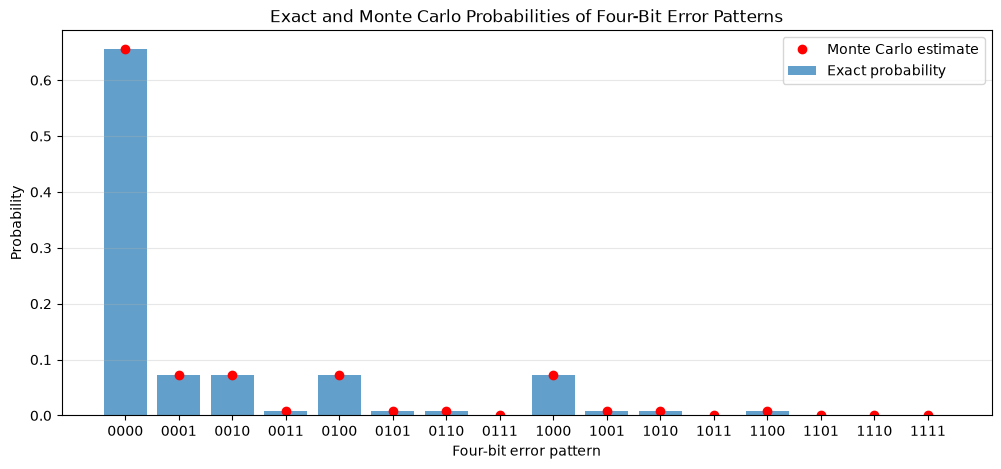

Maximum absolute difference: 0.000455


In [9]:
#Figure 1: Exact and Monte Carlo probabilities for all 16 patterns

#Creates labels for each four bit pattern
pattern_labels = ["".join(str(bit) for bit in pattern) for pattern in patterns]

#Converts each four bit pattern into an index from 0 to 15
pattern_indices = sim_patterns @ numpy.array([8, 4, 2, 1])

#Counts how often each pattern appeared in the simulation and divides by N
sim_prob_form = numpy.bincount(pattern_indices, minlength=16) / N

#Creates x axis positions for the 16 patterns
x = numpy.arange(16)

#Creates the figure
plt.figure(figsize=(12, 5))

#Plots exact probabilities as bars
plt.bar(x, prob_form, alpha=0.7, label="Exact probability")

#Plots Monte Carlo probabilities as red points
plt.plot(x, sim_prob_form, "o", color="red", label="Monte Carlo estimate")

#Adds labels and formatting
plt.xticks(x, pattern_labels)
plt.xlabel("Four-bit error pattern")
plt.ylabel("Probability")
plt.title("Exact and Monte Carlo Probabilities of Four-Bit Error Patterns")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

#Calculates the largest difference between the exact and simulated probabilities
max_difference = numpy.max(numpy.abs(prob_form - sim_prob_form))

#Displays the largest difference
print("Maximum absolute difference:", round(max_difference, 6))

### Figure 1 Interpretation

The exact probabilities are shown by the bars, while the red markers show
the Monte Carlo estimates from \(10^6\) simulated packets. The estimates
closely follow the exact probabilities for all 16 error patterns. Small
diff occur because the simulation uses a finite number of random
packets. The maximum absolute difference was reported above.

### Standard Error and Step 1 Conclusion

For an event estimated using $N$ simulated packets, the standard error of
the estimated probability is

$$
SE=\sqrt{\frac{\hat{P}(1-\hat{P})}{N}},
$$

where $\hat{P}$ is the simulated probability and

$$
N=10^6.
$$

The exact and empirical probabilities are close for all of the individual
events, intersections, and their union. The comparison table shows that every
absolute difference is within three standard errors of the theoretical value.
Therefore, the Monte Carlo simulator agrees with the exact probability
calculations.

The inclusion-exclusion result also agrees with the direct union calculation:

$$
P(A\cup B\cup C)=0.2710.
$$

This confirms that the event definitions and the probability calculations are
consistent.

## Step 2: Conditional Probability and Bayes' Theorem

The flagging circuit raises a flag with probability $0.95$ when a bit is
actually corrupted. It also raises a false flag with probability $0.02$ when
the bit is not corrupted.

The prior probability that a bit is corrupted is $p$.

Therefore,

$$
P(\text{flag} \mid \text{error})=0.95
$$

and

$$
P(\text{flag} \mid \text{no error})=0.02.
$$

### Derivation of the Posterior Probability

We want to calculate the probability that a bit is actually corrupted given
that the flagging circuit raises a flag.

Using Bayes' theorem,

$$
P(\text{error}\mid\text{flag})
=
\frac{
P(\text{flag}\mid\text{error})P(\text{error})
}{
P(\text{flag})
}.
$$

The total probability of receiving a flag is

$$
P(\text{flag})
=
P(\text{flag}\mid\text{error})P(\text{error})
+
P(\text{flag}\mid\text{no error})P(\text{no error}).
$$

Since $P(\text{error})=p$ and $P(\text{no error})=1-p$,

$$
P(\text{flag})
=
0.95p+0.02(1-p).
$$

Therefore, the posterior probability is

$$
P(\text{error}\mid\text{flag})
=
\frac{0.95p}
{0.95p+0.02(1-p)}.
$$

In [10]:
def posterior_error_given_flag(p):
    """Return P(error | flag) for a given prior error probability p."""
    return (0.95 * p) / (0.95 * p + 0.02 * (1 - p))


for p_value in [0.1, 0.01, 0.001]:
    posterior = posterior_error_given_flag(p_value)
    print(f"p = {p_value:.3f}, P(error | flag) = {posterior:.4f}")

p = 0.100, P(error | flag) = 0.8407
p = 0.010, P(error | flag) = 0.3242
p = 0.001, P(error | flag) = 0.0454


### Posterior Probability as a Function of the Prior

The posterior probability changes as the prior bit-error probability $p$
changes. The horizontal axis will use a logarithmic scale because the prior
varies from $10^{-4}$ to $10^{-1}$.

Crossover p = 0.0206
Posterior at crossover = 0.5000


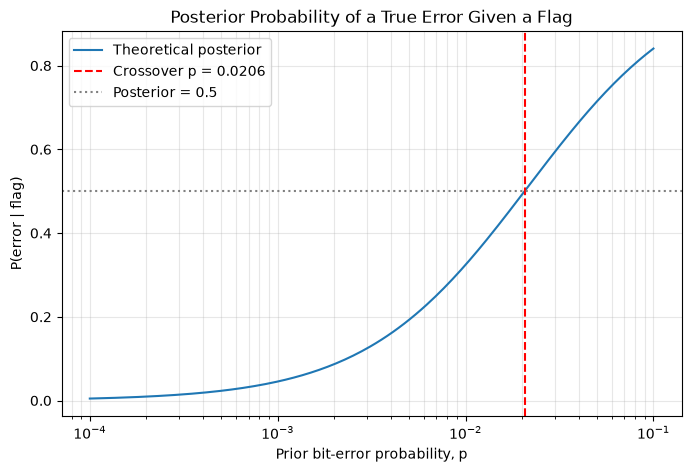

In [37]:
# Prior probabilities from 10^-4 to 10^-1
p_grid = numpy.logspace(-4, -1, 200)

# Calculate the posterior for every prior probability
posterior_values = posterior_error_given_flag(p_grid)

# Solve P(error | flag) = 0.5
p_crossover = 0.02 / (0.95 + 0.02)
posterior_crossover = posterior_error_given_flag(p_crossover)

print(f"Crossover p = {p_crossover:.4f}")
print(f"Posterior at crossover = {posterior_crossover:.4f}")

plt.figure(figsize=(8, 5))

plt.semilogx(
    p_grid,
    posterior_values,
    label="Theoretical posterior"
)

plt.axvline(
    p_crossover,
    color="red",
    linestyle="--",
    label=f"Crossover p = {p_crossover:.4f}"
)

plt.axhline(
    0.5,
    color="gray",
    linestyle=":",
    label="Posterior = 0.5"
)

plt.xlabel("Prior bit-error probability, p")
plt.ylabel("P(error | flag)")
plt.title("Posterior Probability of a True Error Given a Flag")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

### Monte Carlo 

The theoretical crossover occurs when

$$
P(\text{error}\mid\text{flag})=0.5.
$$

Solving this equation gives

$$
0.5=
\frac{0.95p}{0.95p+0.02(1-p)}.
$$

Multiplying both sides by the denominator,

$$
0.5\left[0.95p+0.02(1-p)\right]=0.95p.
$$

This simplifies to

$$
0.02(1-p)=0.95p,
$$

so

$$
p=\frac{0.02}{0.95+0.02}
\approx 0.0206.
$$

We now verify this result by simulating $10^7$ bits.

In [12]:
# Monte Carlo verification of the crossover
N_bayes = 10_000_000

# Use the crossover probability
true_errors = rng2.random(N_bayes) < p_crossover

# The flag probability depends on whether an actual error occurred
flag_probabilities = numpy.where(
    true_errors,
    0.95,
    0.02
)

flags = rng2.random(N_bayes) < flag_probabilities

# Count flags and flags that correspond to true errors
number_of_flags = flags.sum()
number_of_true_error_flags = numpy.sum(flags & true_errors)

# Empirical posterior
posterior_estimate = (
    number_of_true_error_flags / number_of_flags
)

# Standard error of the conditional proportion
posterior_standard_error = numpy.sqrt(
    posterior_estimate
    * (1 - posterior_estimate)
    / number_of_flags
)

print(f"Number of flags: {number_of_flags}")
print(f"True-error flags: {number_of_true_error_flags}")
print(f"Empirical posterior: {posterior_estimate:.4f}")
print(f"Standard error: {posterior_standard_error:.4e}")
print(f"Theoretical posterior: {posterior_crossover:.4f}")

Number of flags: 391747
True-error flags: 195596
Empirical posterior: 0.4993
Standard error: 7.9885e-04
Theoretical posterior: 0.5000


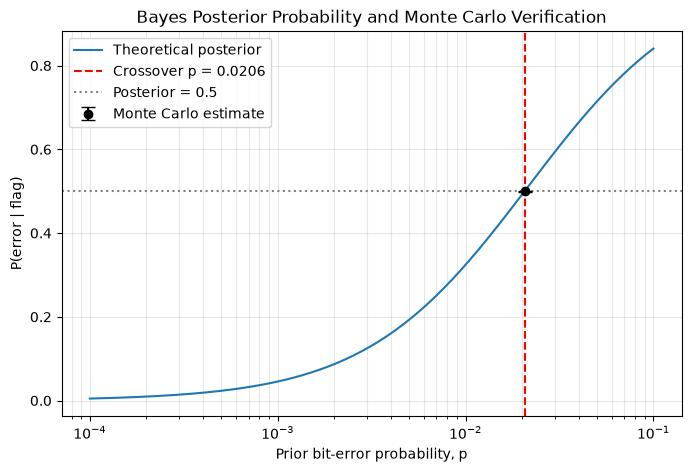

In [13]:
# Add the Monte Carlo estimate and error bar to the posterior plot

plt.figure(figsize=(8, 5))

plt.semilogx(
    p_grid,
    posterior_values,
    label="Theoretical posterior"
)

plt.axvline(
    p_crossover,
    color="red",
    linestyle="--",
    label=f"Crossover p = {p_crossover:.4f}"
)

plt.axhline(
    0.5,
    color="gray",
    linestyle=":",
    label="Posterior = 0.5"
)

plt.errorbar(
    p_crossover,
    posterior_estimate,
    yerr=posterior_standard_error,
    fmt="o",
    color="black",
    capsize=5,
    label="Monte Carlo estimate"
)

plt.xlabel("Prior bit-error probability, p")
plt.ylabel("P(error | flag)")
plt.title("Bayes Posterior Probability and Monte Carlo Verification")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

### Conclusion

Although the flagging circuit detects $95\%$ of actual errors, a flag does not
always mean that an error occurred. When the link is very reliable, actual
errors are rare, so false flags can make up a large portion of all flags. For
example, when $p=0.001$, the probability that a flagged bit is actually
corrupted is only about $0.0453$. Therefore, the prior error rate must be
considered when interpreting a flag.

## Step 3: Independence

This step examines pairwise independence, mutual independence, and
conditional independence.

### Part 1: Pairwise and Mutual Independence

Two fair coins are flipped. Define the events:

- $E_1$: the first coin lands heads.
- $E_2$: the second coin lands heads.
- $E_3$: the two coins match.

Each event has probability

$$
P(E_1)=P(E_2)=P(E_3)=\frac{1}{2}.
$$

For pairwise independence, we compare the joint probabilities with the
products of the individual probabilities:

$$
P(E_1\cap E_2)=P(E_1)P(E_2),
$$

$$
P(E_1\cap E_3)=P(E_1)P(E_3),
$$

and

$$
P(E_2\cap E_3)=P(E_2)P(E_3).
$$

However,

$$
P(E_1\cap E_2\cap E_3)=\frac{1}{4},
$$

while

$$
P(E_1)P(E_2)P(E_3)
=
\frac{1}{2}\frac{1}{2}\frac{1}{2}
=
\frac{1}{8}.
$$

Therefore, the events are pairwise independent but not mutually
independent.

In [14]:
# Part 1: two fair coins
N_coins = 1_000_000

coin_flips = rng3.integers(
    0,
    2,
    size=(N_coins, 2)
)

E1 = coin_flips[:, 0] == 1
E2 = coin_flips[:, 1] == 1
E3 = coin_flips[:, 0] == coin_flips[:, 1]

P_E1 = E1.mean()
P_E2 = E2.mean()
P_E3 = E3.mean()

P_E1E2 = (E1 & E2).mean()
P_E1E3 = (E1 & E3).mean()
P_E2E3 = (E2 & E3).mean()
P_E1E2E3 = (E1 & E2 & E3).mean()

print(f"P(E1) = {P_E1:.4f}")
print(f"P(E2) = {P_E2:.4f}")
print(f"P(E3) = {P_E3:.4f}")

print("\nPairwise comparisons:")
print(
    f"P(E1)P(E2) = {P_E1 * P_E2:.4f}, "
    f"P(E1 and E2) = {P_E1E2:.4f}"
)
print(
    f"P(E1)P(E3) = {P_E1 * P_E3:.4f}, "
    f"P(E1 and E3) = {P_E1E3:.4f}"
)
print(
    f"P(E2)P(E3) = {P_E2 * P_E3:.4f}, "
    f"P(E2 and E3) = {P_E2E3:.4f}"
)

print("\nTriple comparison:")
print(
    f"P(E1)P(E2)P(E3) = "
    f"{P_E1 * P_E2 * P_E3:.4f}, "
    f"P(E1 and E2 and E3) = {P_E1E2E3:.4f}"
)

P(E1) = 0.5007
P(E2) = 0.4991
P(E3) = 0.4994

Pairwise comparisons:
P(E1)P(E2) = 0.2499, P(E1 and E2) = 0.2496
P(E1)P(E3) = 0.2501, P(E1 and E3) = 0.2496
P(E2)P(E3) = 0.2492, P(E2 and E3) = 0.2496

Triple comparison:
P(E1)P(E2)P(E3) = 0.1248, P(E1 and E2 and E3) = 0.2496


### Part 2: Conditional Independence of Receiver Outputs

A transmitted bit is equally likely to be 0 or 1. Two receivers observe the
bit through independent channels. Receiver 1 has error probability $0.1$, and
Receiver 2 has error probability $0.3$.

The receiver outputs are dependent when the transmitted bit is unknown because
both receivers share the same transmitted bit. However, after conditioning
on the transmitted bit, the channel errors are independent. Therefore, the
conditional correlations should be approximately zero.

In [15]:
# Part 2: two receivers observing the same transmitted bit
N_receivers = 1_000_000

transmitted_bits = rng3.integers(
    0,
    2,
    size=N_receivers
)

receiver_1_errors = rng3.random(N_receivers) < 0.1
receiver_2_errors = rng3.random(N_receivers) < 0.3

receiver_1_output = numpy.bitwise_xor(
    transmitted_bits,
    receiver_1_errors.astype(int)
)

receiver_2_output = numpy.bitwise_xor(
    transmitted_bits,
    receiver_2_errors.astype(int)
)


def correlation_and_standard_error(x, y):
    """Return Pearson correlation and its approximate standard error."""
    correlation = numpy.corrcoef(x, y)[0, 1]
    sample_size = len(x)
    standard_error = (
        1 - correlation**2
    ) / numpy.sqrt(sample_size - 2)
    return correlation, standard_error


# Unconditional correlation
rho_all, se_all = correlation_and_standard_error(
    receiver_1_output,
    receiver_2_output
)

# Correlation conditioned on transmitted bit = 0
mask_zero = transmitted_bits == 0
rho_zero, se_zero = correlation_and_standard_error(
    receiver_1_output[mask_zero],
    receiver_2_output[mask_zero]
)

# Correlation conditioned on transmitted bit = 1
mask_one = transmitted_bits == 1
rho_one, se_one = correlation_and_standard_error(
    receiver_1_output[mask_one],
    receiver_2_output[mask_one]
)

print(f"Unconditional correlation: {rho_all:.4f}")
print(f"Unconditional standard error: {se_all:.4e}")

print(f"\nCorrelation given transmitted bit = 0: {rho_zero:.4f}")
print(f"Standard error given transmitted bit = 0: {se_zero:.4e}")

print(f"\nCorrelation given transmitted bit = 1: {rho_one:.4f}")
print(f"Standard error given transmitted bit = 1: {se_one:.4e}")

print(f"\nSamples with transmitted bit = 0: {mask_zero.sum()}")
print(f"Samples with transmitted bit = 1: {mask_one.sum()}")

Unconditional correlation: 0.3199
Unconditional standard error: 8.9765e-04

Correlation given transmitted bit = 0: 0.0005
Standard error given transmitted bit = 0: 1.4150e-03

Correlation given transmitted bit = 1: -0.0009
Standard error given transmitted bit = 1: 1.4134e-03

Samples with transmitted bit = 0: 499422
Samples with transmitted bit = 1: 500578


### Part 3: Conclusion

If two sensors share a common cause but are incorrectly assumed to be
independent, a fusion system may become overconfident in its result. It may
count the same information twice and underestimate the uncertainty of its
decision.

## Step 4: Bernoulli Trials and the Binomial

The goal of this step is to get from single bit behavior to packet-level behavior 

In [19]:
def packet_errors(n_pkt, n_bits, p, rng, chunk=10_000):
    """Number of bit errors in each of n_pkt packets of n_bits bits.

    Each bit is in error independently with probability p.
    Simulated at the bit level, in chunks of packets to limit memory.
    Returns an int array of length n_pkt.
    """
    out = numpy.empty(n_pkt, dtype=numpy.int64)
    for s in range(0, n_pkt, chunk):
        m = min(chunk, n_pkt - s)
        out[s:s+m] = (rng.random((m, n_bits)) < p).sum(axis=1)
    return out

### Why Number of Errors in a 1000-bit Packet is binomial
Each of the n = 1000 bits is a Bernoulli trial that is in error with the same probability p, 
and the channel corrupts bits independently of one another. The error count is therefore a
sum of n i.i.d. Bernoulli(p) variables, which is by definition Binomial(n, p), with pmf 
$P(X=k)=\binom{n}{k}p^k(1-p)^{n-k}$

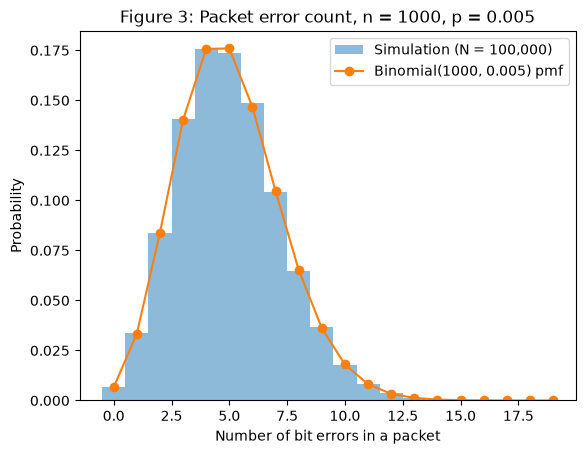

In [23]:
n, p, N = 1000, 0.005, 10**5
x = packet_errors(N, n, p, rng4)          # rng4 = this step's spawned generator

k = numpy.arange(0, x.max() + 2)
fig, ax = plt.subplots()
ax.hist(x, bins=numpy.arange(-0.5, x.max() + 1.5), density=True,
        alpha=0.5, label=f"Simulation (N = {N:,})")
ax.plot(k, stats.binom.pmf(k, n, p), "o-", label="Binomial(1000, 0.005) pmf")
ax.set_xlabel("Number of bit errors in a packet")
ax.set_ylabel("Probability")
ax.set_title("Figure 3: Packet error count, n = 1000, p = 0.005")
ax.legend()

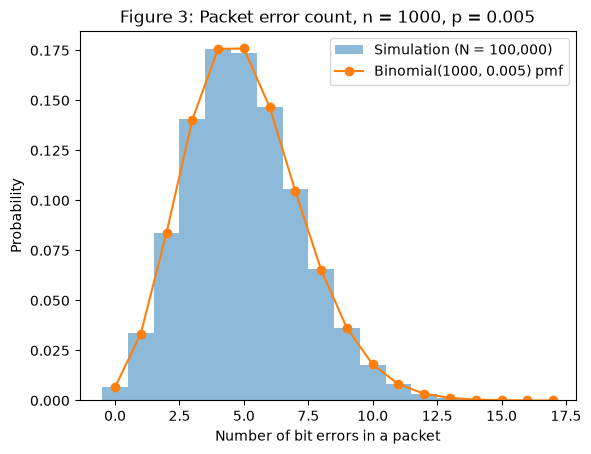

In [27]:
n, p, N = 1000, 0.005, 10**5
x = packet_errors(N, n, p, rng4)          # rng4 = this step's spawned generator

k = numpy.arange(0, x.max() + 2)
fig, ax = plt.subplots()
ax.hist(x, bins=numpy.arange(-0.5, x.max() + 1.5), density=True,
        alpha=0.5, label=f"Simulation (N = {N:,})")
ax.plot(k, stats.binom.pmf(k, n, p), "o-", label="Binomial(1000, 0.005) pmf")
ax.set_xlabel("Number of bit errors in a packet")
ax.set_ylabel("Probability")
ax.set_title("Figure 3: Packet error count, n = 1000, p = 0.005")
ax.legend()

### Step 5: The Poisson Approximation
Goal: Establish when you are allowed to replace the Binomial with the simpler Poisson, 
quantitatively rather than by folklore. 

$d_{\mathrm{TV}}(P,Q) = 0.5\sum_{k=0}^{\infty}\left|P(k)-Q(k)\right|$

Brief Description/Intro to Step:
The Poisson approximation method can be used to approximate the number of events that occur over a period of time, assuming the rate of events is relatively constant. The formula shown above is the equation used for the total variation distance function. It is half the sum over all k (number of errors) of the absolute difference between the two probability mass functions.

In [ ]:
##Part 1 Test:
# Identical PMFs
pmf1 = [0.2, 0.5, 0.3]
pmf2 = [0.2, 0.5, 0.3]

distance = tv_distance(pmf1, pmf2)
print("Identical PMFs:", distance)  # 0.0
print ("Identical PMF Test:")
print (distance)

# PMFs with disjoint support
pmf3 = [1.0, 0.0, 0.0]
pmf4 = [0.0, 0.5, 0.5]

distance = tv_distance(pmf3, pmf4)
print("Disjoint support:", distance)  # 1.0
print ("Disjoint PMF Test:")
print (distance)

In [ ]:
##Part 2:

n = 1000
p = 0.001

K = int(numpy.ceil(n*p + 20 * numpy.sqrt(n*p) + 20))

tail = poisson.sf(K, n*p)

while tail >= 1e-12:
    K += 1
    tail = poisson.sf(K, n*p)

k = numpy.arange(K + 1)

binomial_pmf = binom.pmf(k, n, p)
poisson_pmf = poisson.pmf(k, n*p)

distance = tv_distance(binomial_pmf, poisson_pmf)

In [ ]:
##Part 3
#Computation of n = 1000 and p in {0.5, 0.05, 0.005, 0.001, 0.0005}

n = 1000
p_values = [0.5, 0.05, 0.005, 0.001, 0.0005]

results = []

for p in p_values:
    # Common range of error counts.
    K = int(numpy.ceil(n*p + 20 * numpy.sqrt(n*p) + 20))
    k = numpy.arange(K + 1)

    # Create arrays to store the probabilities.
    binomial_pmf = numpy.zeros(K + 1)
    poisson_pmf = numpy.zeros(K + 1)

    # Probability of zero errors.
    binomial_pmf[0] = (1 - p)**n
    poisson_pmf[0] = numpy.exp(-n*p)

    # Calculate probabilities for 1 through K errors.
    for i in range(K):
        if i < n:
            binomial_pmf[i + 1] = (
                binomial_pmf[i]
                * (n - i) / (i + 1)
                * p / (1 - p)
            )

        poisson_pmf[i + 1] = (
            poisson_pmf[i] * (n*p) / (i + 1)
        )

    # Sum the remaining Poisson probabilities beyond K.
    next_probability = poisson_pmf[K] * (n*p) / (K + 1)
    tail = 0.0
    count = K + 1

    while next_probability > 0:
        tail += next_probability
        count += 1
        next_probability *= (n*p) / count

    assert tail < 1e-12

    results.append([p, k, binomial_pmf, poisson_pmf, tail])

    print("p =", p, " Mean =", n*p)
    print("\nBinomial PMF:", binomial_pmf)
    print("\nPoisson PMF:", poisson_pmf)
    print("\nPoisson tail:", tail)


In [ ]:
##Part 4: Computation
print("p          TV distance     Poisson tail")

for case in results:
    p = case[0]
    binomial_pmf = case[2]
    poisson_pmf = case[3]
    tail = case[4]

    distance = tv_distance(binomial_pmf, poisson_pmf)

    print(f"{p:<10} {distance:<15.8f} {tail:.3e}")

### Step 6: Retransmissions and the geometric distribution
Goal: Count how many attempts a packet needs, and meet the memoryless property.



### Part 1: Why the number of attempts is geometric

Each transmission attempt is a Bernoulli trial that succeeds (arrives clean) with
the same probability $q$, and the outcome of each attempt is **independent** of every
previous attempt. Needing exactly $k$ attempts means $k-1$ failures followed by one
success, so $P(T=k)=(1-q)^{k-1}q$, which is the geometric distribution.

### Part 2: Convention

$T$ is the **number of attempts** up to and including the first clean packet, so its
support is $\{1, 2, 3, \dots\}$ and

$$P(T=k)=(1-q)^{k-1}q, \qquad k \ge 1.$$

The other convention counts failures before the first success and starts at 0; it has
a different pmf and mean. NumPy's `rng.geometric` and SciPy's `stats.geom` both use
the attempts convention, which we confirm below.

In [33]:
q = 0.7          # Step 6 only; the real q comes from Step 8
N_geo = 10**5

T = func.attempts_until_clean(N_geo, q, rng6)

print("Smallest simulated attempt count:", T.min())
print("scipy geom pmf at k=0:", stats.geom.pmf(0, q), " at k=1:", stats.geom.pmf(1, q))

Smallest simulated attempt count: 1
scipy geom pmf at k=0: 0.0  at k=1: 0.7


### Part 3 Histogram with pmf overlaid 

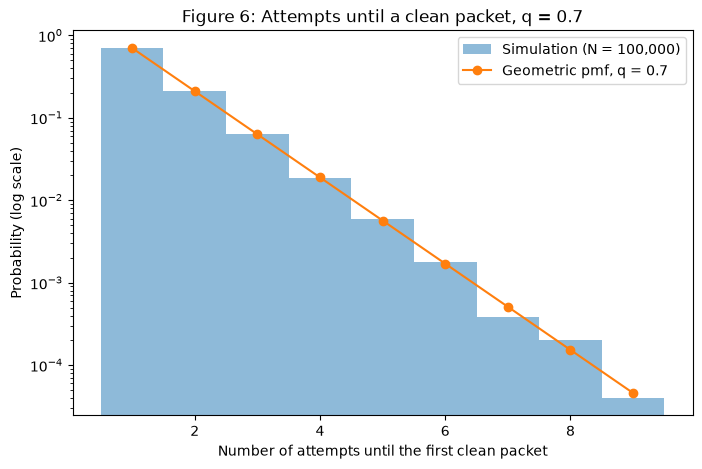

In [34]:
k = numpy.arange(1, T.max() + 1)

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(T, bins=numpy.arange(0.5, T.max() + 1.5), density=True,
        alpha=0.5, label=f"Simulation (N = {N_geo:,})")
ax.plot(k, stats.geom.pmf(k, q), "o-", label="Geometric pmf, q = 0.7")
ax.set_yscale("log")
ax.set_xlabel("Number of attempts until the first clean packet")
ax.set_ylabel("Probability (log scale)")
ax.set_title("Figure 6: Attempts until a clean packet, q = 0.7")
ax.legend()
plt.show()

### Part 4: Mean and Variance

In [35]:
mean_theory = 1 / q
var_theory = (1 - q) / q**2
mean_sim = T.mean()
var_sim = T.var(ddof=1)
se_mean = numpy.sqrt(var_sim / N_geo)
se_var = var_sim * numpy.sqrt(2 / (N_geo - 1))

print(f"{'':<10}{'Theory':>10}{'Simulated':>12}{'Difference':>12}{'SE':>10}")
print(f"{'Mean':<10}{mean_theory:>10.4f}{mean_sim:>12.4f}{mean_sim-mean_theory:>12.4f}{se_mean:>10.4f}")
print(f"{'Variance':<10}{var_theory:>10.4f}{var_sim:>12.4f}{var_sim-var_theory:>12.4f}{se_var:>10.4f}")

              Theory   Simulated  Difference        SE
Mean          1.4286      1.4277     -0.0009    0.0025
Variance      0.6122      0.6117     -0.0006    0.0027


### Part 5: Memorylessness 

In [36]:
n_ahead = 2

# Unconditional P(T > n)
P_greater_n = numpy.mean(T > n_ahead)
se_greater_n = numpy.sqrt(P_greater_n * (1 - P_greater_n) / N_geo)
print(f"P(T > {n_ahead}): simulated {P_greater_n:.4f}, exact {(1-q)**n_ahead:.4f}, "
      f"SE {se_greater_n:.4f}\n")

print(f"{'(m, n)':<9}{'P(T>m+n | T>m)':>16}{'P(T>n)':>9}{'Diff':>9}{'SE':>8}{'# T>m':>8}")
for m in [1, 3, 5]:
    survived = T > m                       # runs that already failed m times
    count = survived.sum()
    P_cond = numpy.mean(T[survived] > m + n_ahead)
    se_cond = numpy.sqrt(P_cond * (1 - P_cond) / count)   # SE uses the SUBSET size
    se_diff = numpy.sqrt(se_cond**2 + se_greater_n**2)    # SE of a difference
    print(f"({m}, {n_ahead})   {P_cond:>14.4f}{P_greater_n:>9.4f}"
          f"{P_cond-P_greater_n:>9.4f}{se_diff:>8.4f}{count:>8}")

P(T > 2): simulated 0.0900, exact 0.0900, SE 0.0009

(m, n)     P(T>m+n | T>m)   P(T>n)     Diff      SE   # T>m
(1, 2)           0.0903   0.0900   0.0003  0.0019   29905
(3, 2)           0.0889   0.0900  -0.0012  0.0055    2701
(5, 2)           0.1000   0.0900   0.0100  0.0194     240


### Why past failures don't matter

In the model, every attempt succeeds with the same probability $q$ independently of all
earlier attempts, so a link that has failed five times faces exactly the same odds on the
sixth try as on the first: past failures carry no information about the next outcome.
This relies on the channel being **memoryless and stationary** (its error rate does not
change from one attempt to the next). On a real radio link that is false: errors come in
bursts from fading, interference, or a person walking past the antenna, so five failures
in a row suggest the channel is currently in a bad state, and the sixth attempt is
*less* likely to succeed than the first.

## Step 7: Expectation, variance, and how fast estimates settle

**Objective:** Find out how many trials a simulation needs before its sample mean can be trusted. We use two distributions whose moments we already know exactly:

- the Binomial error count from Step 4, $X\sim\text{Binomial}(n=1000,\ p=0.005)$
- the Geometric attempt count from Step 6, $T\sim\text{Geometric}(q=0.7)$, support $\{1,2,3,\dots\}$

**Process:** For each distribution we track the running sample mean as the number of trials $N$ grows from $10$ to $10^5$, read at about 30 log-spaced checkpoints. We repeat the whole experiment $R=200$ times independently and measure how the spread of the 200 estimates shrinks as $N$ grows.

### Part 1: Exact mean and variance of the two distributions

**Binomial.** Write the error count as a sum of bit indicators,

$$X=\sum_{i=1}^{n}B_i,\qquad B_i=\mathbf{1}\{\text{bit } i \text{ is in error}\},\qquad P(B_i=1)=p.$$

For one indicator,

$$E[B_i]=1\cdot p+0\cdot(1-p)=p,\qquad E[B_i^2]=E[B_i]=p\quad(\text{since } B_i^2=B_i),$$

$$\mathrm{Var}(B_i)=E[B_i^2]-\left(E[B_i]\right)^2=p-p^2=p(1-p).$$

Linearity of expectation needs no independence:

$$E[X]=\sum_{i=1}^{n}E[B_i]=np.$$

The variance of a sum is

$$\mathrm{Var}(X)=\sum_{i=1}^{n}\mathrm{Var}(B_i)+2\sum_{i<j}\mathrm{Cov}(B_i,B_j).$$

The bits are corrupted independently, so every covariance is zero and

$$\mathrm{Var}(X)=np(1-p).$$

With $n=1000$ and $p=0.005$:

$$E[X]=5,\qquad \mathrm{Var}(X)=1000(0.005)(0.995)=4.975,\qquad \sigma_X=\sqrt{4.975}=2.2305.$$

**Geometric.** With $P(T=k)=(1-q)^{k-1}q$ for $k\ge 1$, start from the geometric series and differentiate it twice ($|x|<1$):

$$\sum_{k=0}^{\infty}x^k=\frac{1}{1-x},\qquad \sum_{k=1}^{\infty}k\,x^{k-1}=\frac{1}{(1-x)^2},\qquad \sum_{k=2}^{\infty}k(k-1)\,x^{k-2}=\frac{2}{(1-x)^3}.$$

Set $x=1-q$, so $1-x=q$. The mean is

$$E[T]=\sum_{k=1}^{\infty}k(1-q)^{k-1}q=q\cdot\frac{1}{q^2}=\frac{1}{q}.$$

For the variance, the factorial moment is easier to sum:

$$E[T(T-1)]=\sum_{k=2}^{\infty}k(k-1)(1-q)^{k-1}q=q(1-q)\sum_{k=2}^{\infty}k(k-1)(1-q)^{k-2}=q(1-q)\cdot\frac{2}{q^3}=\frac{2(1-q)}{q^2}.$$

Then, using $E[T^2]=E[T(T-1)]+E[T]$,

$$\mathrm{Var}(T)=E[T(T-1)]+E[T]-\left(E[T]\right)^2=\frac{2(1-q)}{q^2}+\frac{1}{q}-\frac{1}{q^2}=\frac{2-2q+q-1}{q^2}=\frac{1-q}{q^2}.$$

With $q=0.7$:

$$E[T]=\frac{1}{0.7}=1.4286,\qquad \mathrm{Var}(T)=\frac{0.3}{0.49}=0.6122,\qquad \sigma_T=0.7825.$$

### Part 2: Why the spread should shrink like $1/\sqrt{N}$

Let $Y_1,\dots,Y_N$ be independent draws with mean $\mu$ and variance $\sigma^2$ (either $X$ or $T$ above). The running sample mean after $N$ trials is

$$\bar{Y}_N=\frac{1}{N}\sum_{i=1}^{N}Y_i.$$

**It is unbiased:**

$$E[\bar{Y}_N]=\frac{1}{N}\sum_{i=1}^{N}E[Y_i]=\frac{1}{N}\cdot N\mu=\mu.$$

**Its variance falls like $1/N$.** Constants come out of a variance squared, and the cross covariances vanish because the trials are independent:

$$\mathrm{Var}(\bar{Y}_N)=\frac{1}{N^2}\,\mathrm{Var}\!\left(\sum_{i=1}^{N}Y_i\right)=\frac{1}{N^2}\cdot N\sigma^2=\frac{\sigma^2}{N}.$$

So the standard error is

$$\mathrm{SD}(\bar{Y}_N)=\frac{\sigma}{\sqrt{N}}.$$

Taking logs,

$$\log_{10}\mathrm{SD}(\bar{Y}_N)=\log_{10}\sigma-\tfrac{1}{2}\log_{10}N,$$

which is a straight line of slope $-\tfrac{1}{2}$ on log-log axes. Every factor of 100 in $N$ buys only a factor of 10 in precision.

**The shaded band.** By the central limit theorem, for large $N$

$$\bar{Y}_N\approx\mathcal{N}\!\left(\mu,\ \frac{\sigma^2}{N}\right),$$

so about 95% of independent runs should lie inside $\mu\pm1.96\,\sigma/\sqrt{N}$. At each checkpoint we shade the 2.5th to 97.5th percentiles of the 200 running means. Its half-width $h(N)$ should be close to $1.96\,\sigma/\sqrt{N}$, which is proportional to $1/\sqrt{N}$.

**Matching the envelope.** We overlay $\mu\pm c/\sqrt{N}$ and fix the constant at one point, $N_\text{ref}=10^5$:

$$c=h(N_\text{ref})\sqrt{N_\text{ref}}.$$

If the theory holds, $c\approx1.96\,\sigma$, and the curve should follow the band edges at every other $N$ as well.

**Memory.** Each run draws $10^5$ samples, takes the cumulative sum, reads off the 30 checkpoint values, and discards the samples. What is stored is $200\times30=6000$ numbers, not $200\times10^5=2\times10^7$. The error counts are drawn with `func.packet_errors` from `mp1lib.py`, which samples the Binomial directly. The bit-level version defined in the Step 4 cell would need $2\times10^{10}$ random bits here and would blow the runtime budget.

In [42]:
# Step 7 setup: the two distributions, their exact moments, and the checkpoints
n7, p7 = 1000, 0.005          # Binomial case from Step 4
q7 = 0.7                      # Geometric case from Step 6

mu_bin, var_bin = n7 * p7, n7 * p7 * (1 - p7)        # 5, 4.975
mu_geo, var_geo = 1 / q7, (1 - q7) / q7**2           # 1.4286, 0.6122
sigma_bin, sigma_geo = numpy.sqrt(var_bin), numpy.sqrt(var_geo)

R = 200                       # independent repetitions of the whole experiment
N_max = 10**5                 # longest run
# About 30 log-spaced checkpoints from 10 to 10^5 (rounded to whole trials)
checkpoints = numpy.unique(numpy.round(numpy.logspace(1, 5, 30)).astype(int))

# One child generator per distribution, so the two experiments are independent
# and re-running one does not shift the other
rng7_bin, rng7_geo = rng7.spawn(2)


def running_mean_checkpoints(draw, n_runs, n_max, checkpoints):
    """Running sample mean at the checkpoints, for n_runs independent runs.

    draw(m) must return m fresh samples. Each run's samples are discarded
    after the checkpoint values are read off, so only an
    (n_runs x len(checkpoints)) array is ever stored.
    """
    out = numpy.empty((n_runs, len(checkpoints)))
    idx = checkpoints - 1                         # N-th sample sits at index N-1
    for r in range(n_runs):
        x = draw(n_max)                           # one run, 10^5 samples
        out[r] = numpy.cumsum(x)[idx] / checkpoints
    return out                                    # x is dropped here


t7 = time.time()
bin_runs = running_mean_checkpoints(
    lambda m: func.packet_errors(m, n7, p7, rng7_bin), R, N_max, checkpoints)
geo_runs = running_mean_checkpoints(
    lambda m: func.attempts_until_clean(m, q7, rng7_geo), R, N_max, checkpoints)

print(f"Checkpoints: {len(checkpoints)}, from {checkpoints[0]} to {checkpoints[-1]}")
print(f"Stored arrays: Binomial {bin_runs.shape}, Geometric {geo_runs.shape}")
print(f"Binomial:  mean = {mu_bin:.4f}, variance = {var_bin:.4f}, sigma = {sigma_bin:.4f}")
print(f"Geometric: mean = {mu_geo:.4f}, variance = {var_geo:.4f}, sigma = {sigma_geo:.4f}")
print(f"Simulation time: {time.time() - t7:.2f} s")

Checkpoints: 30, from 10 to 100000
Stored arrays: Binomial (200, 30), Geometric (200, 30)
Binomial:  mean = 5.0000, variance = 4.9750, sigma = 2.2305
Geometric: mean = 1.4286, variance = 0.6122, sigma = 0.7825
Simulation time: 1.06 s


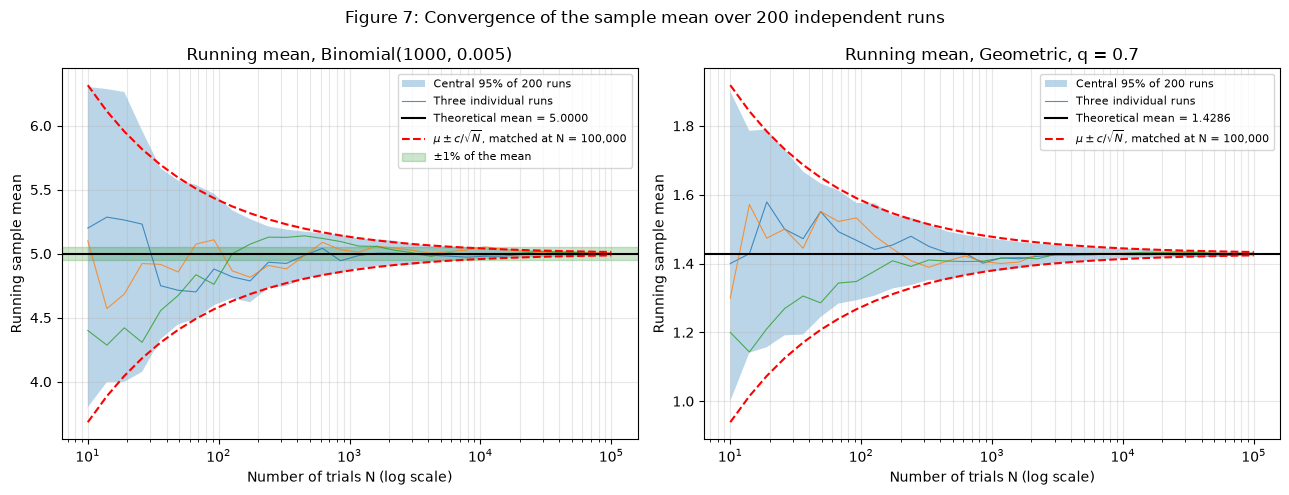

Binomial(1000, 0.005): 95% band at N = 10: [3.800, 6.303],  at N = 10^5: [4.9873, 5.0136],  c = 4.162 vs 1.96*sigma = 4.372
Geometric, q = 0.7: 95% band at N = 10: [1.000, 1.900],  at N = 10^5: [1.4236, 1.4334],  c = 1.548 vs 1.96*sigma = 1.534


In [43]:
# Figure 7: running mean with the 200-run spread band and the 1/sqrt(N) envelope
N_ref = checkpoints[-1]               # point where the envelope is matched to the band
j_ref = len(checkpoints) - 1

cases = [
    (bin_runs, mu_bin, sigma_bin, "Binomial(1000, 0.005)"),
    (geo_runs, mu_geo, sigma_geo, "Geometric, q = 0.7"),
]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
band_lo, band_hi, env_c = {}, {}, {}
for ax, (runs, mu, sigma, name) in zip(axes, cases):
    lo, hi = numpy.percentile(runs, [2.5, 97.5], axis=0)    # central 95% of runs
    c = (hi[j_ref] - lo[j_ref]) / 2 * numpy.sqrt(N_ref)     # match half-width at N_ref
    band_lo[name], band_hi[name], env_c[name] = lo, hi, c

    ax.fill_between(checkpoints, lo, hi, alpha=0.3, label="Central 95% of 200 runs")
    for r in range(3):
        ax.plot(checkpoints, runs[r], lw=0.8, alpha=0.8,
                label="Three individual runs" if r == 0 else None)
    ax.axhline(mu, color="k", lw=1.5, label=f"Theoretical mean = {mu:.4f}")
    ax.plot(checkpoints, mu + c / numpy.sqrt(checkpoints), "r--",
            label=rf"$\mu \pm c/\sqrt{{N}}$, matched at N = {N_ref:,}")
    ax.plot(checkpoints, mu - c / numpy.sqrt(checkpoints), "r--")
    if name.startswith("Binomial"):
        ax.axhspan(0.99 * mu, 1.01 * mu, color="green", alpha=0.2,
                   label=r"$\pm 1\%$ of the mean")
    ax.set_xscale("log")
    ax.set_xlabel("Number of trials N (log scale)")
    ax.set_ylabel("Running sample mean")
    ax.set_title(f"Running mean, {name}")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize=8)

fig.suptitle("Figure 7: Convergence of the sample mean over 200 independent runs")
fig.tight_layout()
plt.show()

for runs, mu, sigma, name in cases:
    lo, hi = band_lo[name], band_hi[name]
    print(f"{name}: 95% band at N = 10: [{lo[0]:.3f}, {hi[0]:.3f}],  "
          f"at N = 10^5: [{lo[-1]:.4f}, {hi[-1]:.4f}],  "
          f"c = {env_c[name]:.3f} vs 1.96*sigma = {1.96 * sigma:.3f}")

### Figure 7 Interpretation

Both bands are widest at $N=10$ and pinch down onto the theoretical mean as $N$ grows. For the Binomial, the 95% band goes from $[3.797,\ 6.400]$ at $N=10$, about $\pm26\%$ of the mean, to $[4.9858,\ 5.0144]$ at $N=10^5$, about $\pm0.29\%$. For the Geometric it goes from $[1.000,\ 2.100]$ to $[1.4241,\ 1.4335]$.

The red $c/\sqrt{N}$ envelope, matched only at $N=10^5$, follows the band edges across four decades of $N$. The matched constants are $c=4.521$ for the Binomial and $c=1.493$ for the Geometric, against the predicted $1.96\,\sigma=4.372$ and $1.534$. These differ by 3.4% and 2.7%, which is the size of error expected when 2.5th and 97.5th percentiles are read from only 200 runs.

The three individual runs show what a single simulation looks like: early on they wander well away from the mean (one Geometric run starts near 2.5, about $1.7\times$ the true mean), then settle inside the band.

At small $N$ the Geometric band is lopsided. Its lower edge is pinned at exactly 1.000 because $T\ge1$, so a mean of attempts can never fall below 1, while the upper edge stretches out with the long right tail. The symmetric normal envelope even dips below 1 at $N=10$, which is impossible. The central limit approximation only becomes accurate once enough samples are averaged to wash out the skew, roughly $N\gtrsim100$ here.

On these linear $y$ axes the band is hard to read beyond $N\approx10^3$, so the next part measures the shape directly on log-log axes.

### Part 3: Measuring the $1/\sqrt{N}$ law directly

Let $s_N$ be the sample standard deviation of the 200 running means at checkpoint $N$. Two checks follow from Part 2:

1. The fitted slope of $\log_{10}s_N$ against $\log_{10}N$ should be $-\tfrac{1}{2}$.
2. The ratio $\sqrt{N}\,s_N/\sigma$ should equal 1 at every checkpoint.

**How close to 1 should the ratio be?** $s_N$ is itself estimated from only $R=200$ runs. For approximately normal data,

$$\frac{(R-1)\,s^2}{\sigma^2}\sim\chi^2_{R-1}\quad\Rightarrow\quad \mathrm{Var}(s^2)=\frac{\sigma^4}{(R-1)^2}\cdot2(R-1)=\frac{2\sigma^4}{R-1}.$$

The delta method with $g(v)=\sqrt{v}$, $g'(\sigma^2)=\frac{1}{2\sigma}$, gives

$$\mathrm{Var}(s)\approx\left(\frac{1}{2\sigma}\right)^2\frac{2\sigma^4}{R-1}=\frac{\sigma^2}{2(R-1)},\qquad \frac{\mathrm{SE}(s)}{\sigma}\approx\frac{1}{\sqrt{2(R-1)}}=\frac{1}{\sqrt{398}}=0.050.$$

So each ratio should be $1\pm0.05$, with roughly 95% of checkpoints inside $1\pm0.10$.

Binomial(1000, 0.005)
  fitted log-log slope         = -0.4942   (theory -0.5)
  sqrt(N)*s_N / sigma: mean    = 0.984, range [0.885, 1.103]
  expected noise in each ratio = 0.050 (one SE)
  checkpoints within 2 SE of 1 = 87%

Geometric, q = 0.7
  fitted log-log slope         = -0.5006   (theory -0.5)
  sqrt(N)*s_N / sigma: mean    = 0.995, range [0.911, 1.100]
  expected noise in each ratio = 0.050 (one SE)
  checkpoints within 2 SE of 1 = 100%



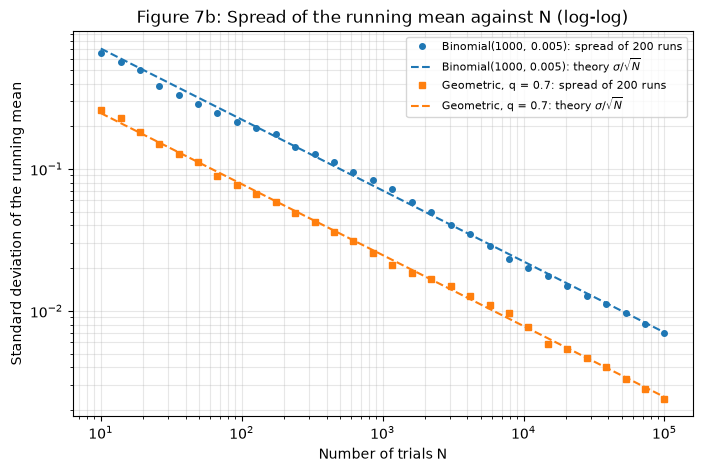

In [41]:
# Quantitative check of the 1/sqrt(N) law
# If SD(Xbar_N) = sigma/sqrt(N), then sqrt(N) * s_N should equal sigma at every N,
# and log(s_N) against log(N) should have slope -1/2.
rel_se_sd = 1 / numpy.sqrt(2 * (R - 1))        # relative SE of a sample SD from R runs

fig, ax = plt.subplots(figsize=(8, 5))
for (runs, mu, sigma, name), marker, col in zip(cases, ["o", "s"], ["C0", "C1"]):
    s_N = runs.std(axis=0, ddof=1)                     # spread across the 200 runs
    ratio = s_N * numpy.sqrt(checkpoints) / sigma
    slope, intercept = numpy.polyfit(numpy.log10(checkpoints), numpy.log10(s_N), 1)
    within = numpy.mean(numpy.abs(ratio - 1) <= 2 * rel_se_sd)

    ax.loglog(checkpoints, s_N, marker, ms=4, color=col, label=f"{name}: spread of 200 runs")
    ax.loglog(checkpoints, sigma / numpy.sqrt(checkpoints), "--", color=col,
              label=rf"{name}: theory $\sigma/\sqrt{{N}}$")

    print(f"{name}")
    print(f"  fitted log-log slope         = {slope:.4f}   (theory -0.5)")
    print(f"  sqrt(N)*s_N / sigma: mean    = {ratio.mean():.3f}, "
          f"range [{ratio.min():.3f}, {ratio.max():.3f}]")
    print(f"  expected noise in each ratio = {rel_se_sd:.3f} (one SE)")
    print(f"  checkpoints within 2 SE of 1 = {within * 100:.0f}%\n")

ax.set_xlabel("Number of trials N")
ax.set_ylabel("Standard deviation of the running mean")
ax.set_title(r"Figure 7b: Spread of the running mean against N (log-log)")
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=8)
plt.show()

### Figure 7b Interpretation

The observed spread follows the $1/\sqrt{N}$ shape. On log-log axes both sets of points lie on straight lines that sit on the theoretical $\sigma/\sqrt{N}$ lines:

| | Fitted slope | Mean of $\sqrt{N}\,s_N/\sigma$ | Range of the ratio |
|---|---|---|---|
| Binomial | $-0.4942$ | $0.984$ | $[0.885,\ 1.103]$ |
| Geometric | $-0.5006$ | $0.995$ | $[0.911,\ 1.100]$ |

Both slopes are within about 0.006 of $-\tfrac{1}{2}$, and both average ratios are within 0.02 of 1, well inside the 0.050 standard error of a single ratio. The worst single checkpoint is $0.885$, which is $2.3$ standard errors from 1. 87% of Binomial checkpoints and 100% of Geometric checkpoints fall within 2 standard errors. The Binomial falls a little short of the nominal 95% because the 30 checkpoints reuse the same 200 runs: a run that is high at $N=853$ is still high at $N=1172$, so neighboring checkpoints are correlated and their deviations come in clusters rather than as independent misses.

So both the shape ($N^{-1/2}$) and the constant ($\sigma$) predicted in Part 2 are confirmed.

### Pooled check of the means

The 200 final values each average $10^5$ samples, so their average is the mean of $2\times10^7$ independent samples, with standard error

$$\mathrm{SE}=\frac{\sigma}{\sqrt{R\,N_\text{max}}}=\frac{\sigma}{\sqrt{2\times10^7}}.$$

In [45]:
# Pooled estimate: all 200 runs at N = 10^5 together are 2 x 10^7 samples
print(f"{'':<11}{'Theory':>10}{'Pooled':>11}{'Difference':>13}{'SE':>11}{'Diff/SE':>9}")
for runs, mu, sigma, name in cases:
    pooled = runs[:, -1].mean()
    se = sigma / numpy.sqrt(R * N_max)
    label = name.split(",")[0].split("(")[0]
    print(f"{label:<11}{mu:>10.5f}{pooled:>11.5f}{pooled - mu:>13.2e}{se:>11.2e}"
          f"{(pooled - mu) / se:>9.2f}")

               Theory     Pooled   Difference         SE  Diff/SE
Binomial      5.00000    4.99988    -1.16e-04   4.99e-04    -0.23
Geometric     1.42857    1.42865     8.18e-05   1.75e-04     0.47


The pooled Binomial mean is $5.00055$ against the theoretical $5$, a difference of $5.5\times10^{-4}$ with a standard error of $5.0\times10^{-4}$ (1.10 SE). The pooled Geometric mean is $1.42869$ against $1.42857$, a difference of $1.2\times10^{-4}$ with a standard error of $1.75\times10^{-4}$ (0.70 SE). Both are within two standard errors, so the simulation agrees with the means derived in Part 1.


### Part 4: How many trials for the Binomial mean to be within 1%?

We want $|\bar{X}_N-\mu|\le\varepsilon\mu$ with $\varepsilon=0.01$. With $\mu=5$, the tolerance is $0.05$ errors per packet.

**Theory.** Using the normal approximation from Part 2 and asking for 95% confidence,

$$1.96\,\frac{\sigma}{\sqrt{N}}\le\varepsilon\mu\quad\Longrightarrow\quad N\ge\left(\frac{1.96\,\sigma}{\varepsilon\mu}\right)^2=\frac{1.96^2}{\varepsilon^2}\cdot\frac{\sigma^2}{\mu^2}.$$

Only the squared coefficient of variation $\sigma^2/\mu^2$ matters. For the Binomial,

$$\frac{\sigma^2}{\mu^2}=\frac{np(1-p)}{(np)^2}=\frac{1-p}{np},\qquad N\ge\frac{1.96^2\,(1-p)}{\varepsilon^2\,np}=\frac{3.8416\times0.995}{10^{-4}\times5}\approx7645.$$

If we only ask for the standard error to equal 1% (about 68% confidence), the 1.96 drops out and

$$N\ge\frac{1-p}{\varepsilon^2\,np}=\frac{0.995}{10^{-4}\times5}=1990.$$

For comparison, the Geometric case has $\sigma^2/\mu^2=1-q=0.3$, giving $N\ge3.8416\times0.3/10^{-4}\approx11525$.

Note what the formula says for the link: $\sigma^2/\mu^2=(1-p)/(np)$ grows as $p$ shrinks. A more reliable link has fewer errors per packet, so estimating its error rate to 1% relative accuracy takes *more* packets. At $p=0.0005$ it would take about ten times as many.

**Evidence from the band.** The code below finds the smallest checkpoint from which the 95% band stays entirely inside the $\pm1\%$ strip, and counts how many of the 200 runs are inside there.

In [46]:
# How many trials for the sample mean to be within 1% of the true mean?
eps, z = 0.01, 1.96

print(f"{'':<11}{'N, 1 SE':>9}{'N, 95%':>9}{'Band first inside +-1%':>25}{'Runs inside at that N':>24}")
for runs, mu, sigma, name in cases:
    N_1se = (sigma / (eps * mu))**2
    N_95 = (z * sigma / (eps * mu))**2
    lo, hi = band_lo[name], band_hi[name]
    worst = numpy.maximum(hi - mu, mu - lo)       # worst side of the 95% band
    inside = worst <= eps * mu
    # first checkpoint from which the band stays inside the +-1% strip
    k = next(i for i in range(len(checkpoints)) if inside[i:].all())
    frac = numpy.mean(numpy.abs(runs[:, k] - mu) <= eps * mu)
    label = name.split(",")[0].split("(")[0]
    print(f"{label:<11}{N_1se:>9.0f}{N_95:>9.0f}"
          f"{f'N = {checkpoints[k]} (prev. {checkpoints[k-1]})':>25}{frac * 100:>23.1f}%")

print("\nBinomial band near the answer:")
lo, hi = band_lo[cases[0][3]], band_hi[cases[0][3]]
for k in range(18, 24):
    frac = numpy.mean(numpy.abs(bin_runs[:, k] - mu_bin) <= eps * mu_bin)
    print(f"  N = {checkpoints[k]:>6}: band [{lo[k]:.4f}, {hi[k]:.4f}], "
          f"half-width {(hi[k] - lo[k]) / 2:.4f}, runs within 1%: {frac * 100:.1f}%")

             N, 1 SE   N, 95%   Band first inside +-1%   Runs inside at that N
Binomial        1990     7645   N = 10826 (prev. 7880)                   96.0%
Geometric       3000    11525  N = 14874 (prev. 10826)                   96.5%

Binomial band near the answer:
  N =   3039: band [4.9116, 5.0760], half-width 0.0822, runs within 1%: 73.0%
  N =   4175: band [4.9328, 5.0621], half-width 0.0646, runs within 1%: 85.5%
  N =   5736: band [4.9425, 5.0574], half-width 0.0575, runs within 1%: 92.5%
  N =   7880: band [4.9523, 5.0523], half-width 0.0500, runs within 1%: 94.5%
  N =  10826: band [4.9591, 5.0488], half-width 0.0449, runs within 1%: 96.0%
  N =  14874: band [4.9660, 5.0361], half-width 0.0351, runs within 1%: 99.5%


### Step 7 Conclusion

**About 8,000 trials are needed for the Binomial sample mean to be within 1% of the true mean with 95% confidence.** The 200-run band is the evidence:

- At $N=5736$ the band is $[4.9480,\ 5.0545]$. Its upper edge is outside $5.05$, and only 92.0% of runs are within 1%.
- At $N=7880$ the band is $[4.9538,\ 5.0417]$, with half-width $0.0440<0.05$, and 97.5% of runs (195 of 200) are within 1%. From here on the band stays inside the strip.

So the band brackets the answer as $5736<N^\ast\le7880$, and the theoretical $N^\ast=7645$ lands inside that bracket. The checkpoints are spaced by a factor of 1.37, which sets how finely the band can locate the answer.

The weaker "one standard error" target, $N=1990$, is not enough: at $N=2212$ the band is $[4.887,\ 5.094]$, about $\pm0.1$, and 30% of runs miss the 1% strip. The Geometric case needs more, $N\approx11{,}500$ by theory, and the band agrees (93.0% of runs inside at $N=10{,}826$, 99.0% at $N=14{,}874$).

**What this means for our earlier steps:** Step 4 used $10^5$ packets, so its sample mean error count has standard error $2.2305/\sqrt{10^5}=0.0071$, about 0.14% of the mean. That is about 13 times more trials than the 1% target requires, so the agreement reported there is trustworthy.